In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split 

In [26]:

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)
class LinearRegression:
    def __init__(self, lr=0.01, n_iterations=1000):
        self.lr = lr
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.costs = []
    
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.costs = []          

        for _ in range(self.n_iterations):
          y_predicted = np.dot(X, self.weights) + self.bias
          self.costs.append(np.mean((y_predicted - y) ** 2))   
    

        for _ in range(self.n_iterations):
            y_predicted = np.dot(X, self.weights) + self.bias
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            self.costs.append(mse(y, y_predicted))

            self.weights -= self.lr * dw
            self.bias -= self.lr * db
        
    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

In [27]:
x,y =  datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=4)
x_train , x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
rgr = LinearRegression()
rgr.fit(x_train,y_train)
y_pred = rgr.predict(x_test)

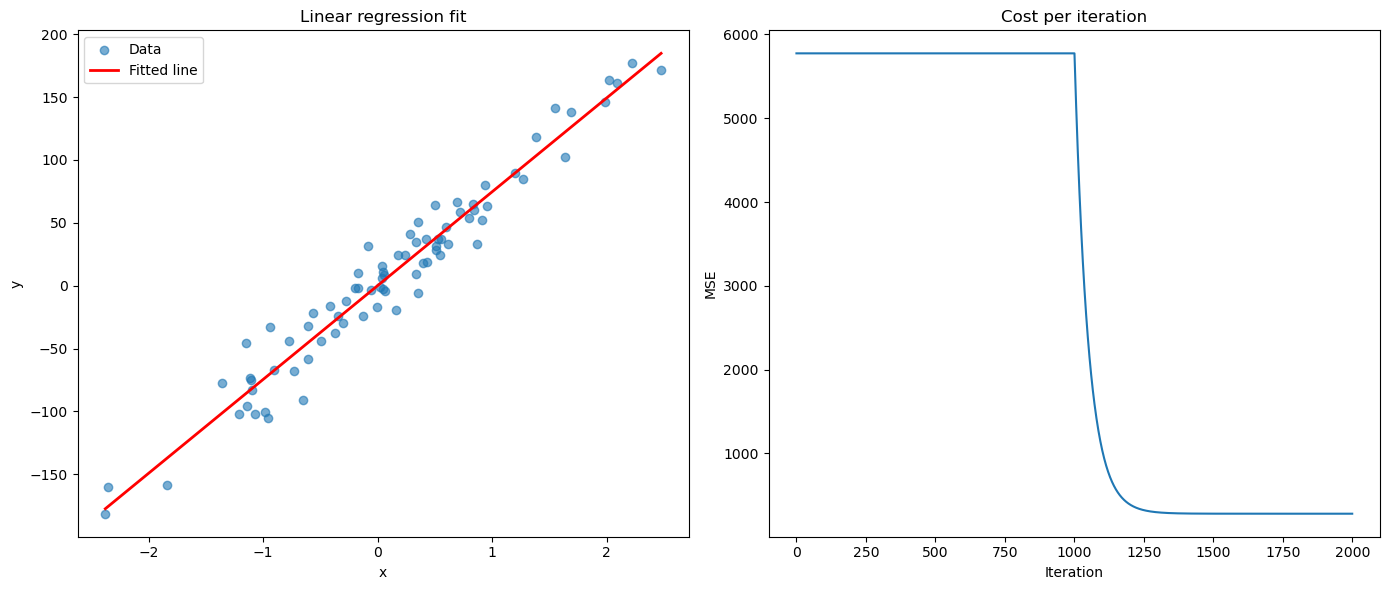

In [28]:
x_line = np.linspace(x_train.min(), x_train.max(), 100).reshape(-1, 1)
y_line = rgr.predict(x_line)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(x_train, y_train, alpha=0.6, label="Data")
ax1.plot(x_line, y_line, color="red", linewidth=2, label="Fitted line")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Linear regression fit")
ax1.legend()
ax2.plot(rgr.costs)
ax2.set_xlabel("Iteration")
ax2.set_ylabel("MSE")
ax2.set_title("Cost per iteration")

plt.tight_layout()
plt.show()

In [29]:


def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

print(f"MSE: {mse(y_test, y_pred):.2f}")
print(f"R2:  {r2_score(y_test, y_pred):.3f}")


MSE: 325.72
R2:  0.928


# comparing with sklearn's model 

In [30]:
from sklearn.linear_model import LinearRegression as SkLR
sk = SkLR().fit(x_train, y_train)
print("my model:", rgr.weights, rgr.bias)
print("sklearn's model:", sk.coef_, sk.intercept_)

my model: [74.57273988] 0.06300511249950763
sklearn's model: [74.57869703] 0.0584761050101239
